In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from analyzer import clean_data

df = pd.read_csv("data.csv/data.csv", encoding="ISO-8859-1")
final = clean_data(df)
final.shape

(392652, 9)

In [2]:
daily = final.set_index("Date")["Revenue"].resample("D").sum()
daily.head(10)

Date
2010-12-01    46192.49
2010-12-02    45675.97
2010-12-03    23876.63
2010-12-04        0.00
2010-12-05    31361.28
2010-12-06    31009.33
2010-12-07    53730.96
2010-12-08    39094.20
2010-12-09    38193.91
2010-12-10    33488.38
Freq: D, Name: Revenue, dtype: float64

In [3]:
len(daily)
daily.describe()
(daily == 0).sum()

np.int64(69)

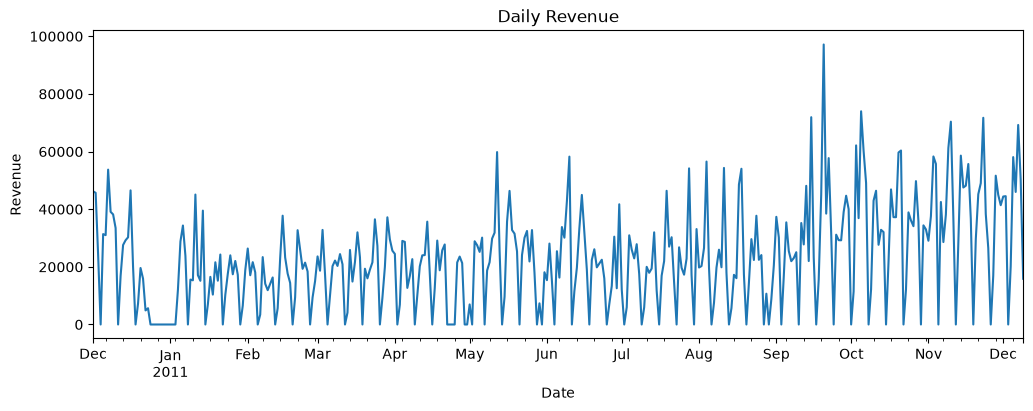

In [4]:
daily.plot(figsize=(12, 4))
plt.title("Daily Revenue")
plt.ylabel("Revenue")
plt.show()

In [8]:
len(daily)

374

In [10]:
data = daily.to_frame(name="Revenue")
data.head()

,Revenue
Date,
2010-12-01,46192.49
2010-12-02,45675.97
2010-12-03,23876.63
2010-12-04,0.00
2010-12-05,31361.28


In [11]:
data["day_of_week"] = data.index.dayofweek
data["month"] = data.index.month
data.head(10)

,Revenue,day_of_week,month
Date,,,
2010-12-01,46192.49,2,12
2010-12-02,45675.97,3,12
2010-12-03,23876.63,4,12
2010-12-04,0.00,5,12
2010-12-05,31361.28,6,12
2010-12-06,31009.33,0,12
2010-12-07,53730.96,1,12
2010-12-08,39094.20,2,12
2010-12-09,38193.91,3,12


In [12]:
data["lag_1"] = data["Revenue"].shift(1)
data["lag_7"] = data["Revenue"].shift(7)
data.head(10)

,Revenue,day_of_week,month,lag_1,lag_7
Date,,,,,
2010-12-01,46192.49,2,12,NaN,NaN
2010-12-02,45675.97,3,12,46192.49,NaN
2010-12-03,23876.63,4,12,45675.97,NaN
2010-12-04,0.00,5,12,23876.63,NaN
2010-12-05,31361.28,6,12,0.00,NaN
2010-12-06,31009.33,0,12,31361.28,NaN
2010-12-07,53730.96,1,12,31009.33,NaN
2010-12-08,39094.20,2,12,53730.96,46192.49
2010-12-09,38193.91,3,12,39094.20,45675.97


In [13]:
data = data.dropna()
data.shape

(367, 5)

In [14]:
features = ["day_of_week", "month", "lag_1", "lag_7"]
X = data[features]
y = data["Revenue"]
X.shape, y.shape

((367, 4), (367,))

In [15]:
features = ["day_of_week", "month", "lag_1", "lag_7"]
X = data[features]
y = data["Revenue"]

split = int(len(data) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

X_train.shape, X_test.shape

((293, 4), (74, 4))

In [17]:
X_train.index.max()

Timestamp('2011-09-26 00:00:00')

In [18]:

X_test.index.min()

Timestamp('2011-09-27 00:00:00')

In [19]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-1243.79, -124.51, 0.19, 0.5 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['day_of_week','month','lag_1','lag_7']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.054e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [20]:
pred = model.predict(X_test)

results = pd.DataFrame({"actual": y_test, "predicted": pred.round(0)})
results.head(10)

,actual,predicted
Date,,
2011-09-27,29212.32,62229.0
2011-09-28,39001.91,31640.0
2011-09-29,44671.27,41860.0
2011-09-30,40023.44,28689.0
2011-10-01,0.00,10575.0
2011-10-02,11479.98,17414.0
2011-10-03,62143.07,26078.0
2011-10-04,36899.69,34299.0
2011-10-05,73975.57,33220.0


In [21]:
pd.Series(model.coef_, index=features)

day_of_week   -1243.792837
month          -124.511278
lag_1             0.187350
lag_7             0.499947
dtype: float64

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    r2 = r2_score(y_true, y_pred)
    return {"MAE": round(mae), "RMSE": round(rmse), "R2": round(r2, 2)}

evaluate(y_test, pred)

{'MAE': 12441, 'RMSE': 15834, 'R2': 0.36}

In [23]:
evaluate(y_test, X_test["lag_1"])

{'MAE': 19459, 'RMSE': 24512, 'R2': -0.54}

In [24]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

evaluate(y_test, rf_pred)

{'MAE': 12009, 'RMSE': 16127, 'R2': 0.33}

In [25]:
pd.DataFrame({
    "Baseline": evaluate(y_test, X_test["lag_1"]),
    "Linear Regression": evaluate(y_test, pred),
    "Random Forest": evaluate(y_test, rf_pred),
})

,Baseline,Linear Regression,Random Forest
MAE,19459.00,12441.00,12009.00
RMSE,24512.00,15834.00,16127.00
R2,-0.54,0.36,0.33


In [26]:
daily.mean()

np.float64(22896.39578609626)

In [27]:
best_mae = 0  # replace 0 with your best model's MAE from the table
round(best_mae / daily.mean() * 100)

0

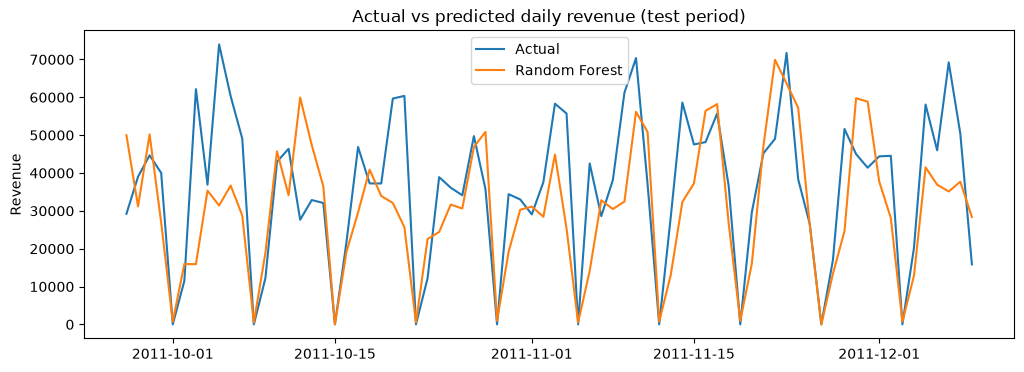

In [28]:
plt.figure(figsize=(12, 4))
plt.plot(y_test.index, y_test, label="Actual")
plt.plot(y_test.index, rf_pred, label="Random Forest")
plt.legend()
plt.title("Actual vs predicted daily revenue (test period)")
plt.ylabel("Revenue")
plt.show()

In [29]:
from analyzer import clean_data, run_forecast

result = run_forecast(clean_data(df))
result["metrics"]


ImportError: cannot import name 'run_forecast' from 'analyzer' (C:\Users\HIRAL RATHOD\OneDrive\Documents\HIRAL\projects\Personal project\ecommerce-sales-analyzer\analyzer.py)

In [30]:
import pandas as pd
from analyzer import clean_data, run_forecast

df = pd.read_csv("data.csv/data.csv", encoding="ISO-8859-1")
result = run_forecast(clean_data(df))
result["metrics"]

ImportError: cannot import name 'run_forecast' from 'analyzer' (C:\Users\HIRAL RATHOD\OneDrive\Documents\HIRAL\projects\Personal project\ecommerce-sales-analyzer\analyzer.py)

In [31]:
import pandas as pd
from analyzer import clean_data, run_forecast

df = pd.read_csv("data.csv/data.csv", encoding="ISO-8859-1")
result = run_forecast(clean_data(df))
result["metrics"]

ImportError: cannot import name 'run_forecast' from 'analyzer' (C:\Users\HIRAL RATHOD\OneDrive\Documents\HIRAL\projects\Personal project\ecommerce-sales-analyzer\analyzer.py)

In [32]:
import importlib
import analyzer
importlib.reload(analyzer)

print(hasattr(analyzer, "run_forecast"))

True


In [33]:
from analyzer import clean_data, run_forecast

df = pd.read_csv("data.csv/data.csv", encoding="ISO-8859-1")
result = run_forecast(clean_data(df))
result["metrics"]

,Baseline,Linear Regression,Random Forest
MAE,19459.00,12441.00,12009.00
RMSE,24512.00,15834.00,16127.00
R2,-0.54,0.36,0.33


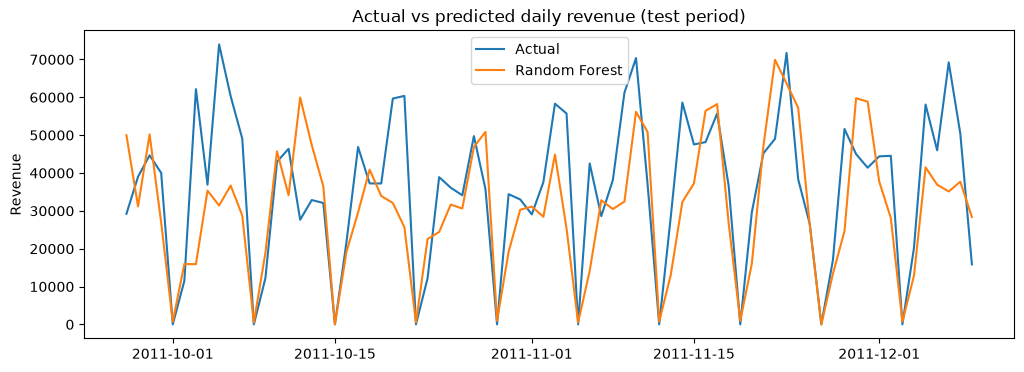

In [34]:
actual = result["actual"]
rf_pred = result["predictions"]["Random Forest"]

plt.figure(figsize=(12, 4))
plt.plot(actual.index, actual, label="Actual")
plt.plot(actual.index, rf_pred, label="Random Forest")
plt.legend()
plt.title("Actual vs predicted daily revenue (test period)")
plt.ylabel("Revenue")
plt.show()